In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from design.fitter import PhotonicFitter
from verification.stability import robustness

fitter = PhotonicFitter(smooth_sigma=4.0)

initial_desig = "y_branch"
target_ratio = 0.5

/Users/samuelnoger/Programms/env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
ratios = [0.2, 0.3, 0.5, 0.7, 0.8]
sweep_results = {}

for r in ratios:
    res = fitter.fit(
        target_ratio=r,
        init_mode=initial_desig,
        steps=180,
        lr=0.05,
        robust_delta=0.3,
        robust_start=0.65,
    )
    rob = robustness(fitter, res["rho"], target_ratio=r, biases=(-1, 0, 1), wls=(1.53, 1.55, 1.57), verbose=False)
    sweep_results[r] = {"fit": res, "rob": rob}

Fitting [FDFD Adjoint] (20/80): 100%|██████████| 180/180 [02:51<00:00,  1.05it/s, T1=19.1%, T2=77.3%, Tot=96.5%, beta=12.0]


 [FDFD Adjoint Fit in 171.7s]



Fitting [FDFD Adjoint] (30/70): 100%|██████████| 180/180 [02:53<00:00,  1.04it/s, T1=29.0%, T2=67.6%, Tot=96.6%, beta=12.0]


 [FDFD Adjoint Fit in 173.2s]



Fitting [FDFD Adjoint] (50/50): 100%|██████████| 180/180 [02:53<00:00,  1.04it/s, T1=48.3%, T2=48.3%, Tot=96.7%, beta=12.0]


 [FDFD Adjoint Fit in 173.7s]



Fitting [FDFD Adjoint] (70/30): 100%|██████████| 180/180 [02:51<00:00,  1.05it/s, T1=67.6%, T2=29.0%, Tot=96.6%, beta=12.0]


 [FDFD Adjoint Fit in 171.6s]



Fitting [FDFD Adjoint] (80/20): 100%|██████████| 180/180 [02:52<00:00,  1.04it/s, T1=77.3%, T2=19.1%, Tot=96.5%, beta=12.0]


 [FDFD Adjoint Fit in 172.8s]



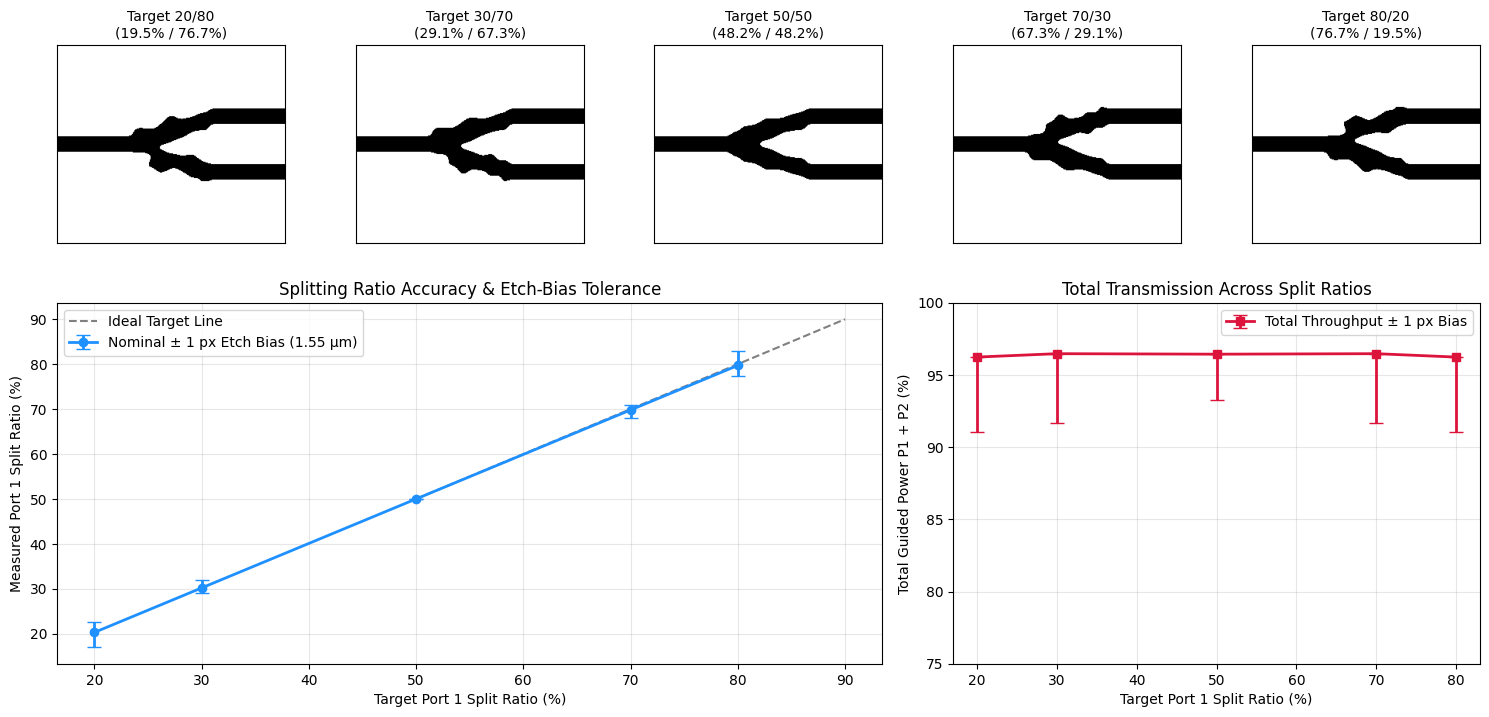

In [4]:
fig = plt.figure(figsize=(15, 7.5))
gs = fig.add_gridspec(2, 5, height_ratios=[1.0, 1.15])

# Top row: Optimized binary silicon topologies for each split ratio
for idx, r in enumerate(ratios):
    ax = fig.add_subplot(gs[0, idx])
    eps_grid = sweep_results[r]["fit"]["eps_norm"]
    t1 = sweep_results[r]["fit"]["t1_fit"] * 100
    t2 = sweep_results[r]["fit"]["t2_fit"] * 100
    ax.imshow(eps_grid.T, cmap="Greys", origin="lower")
    ax.set_title(f"Target {r*100:.0f}/{(1-r)*100:.0f}\n({t1:.1f}% / {t2:.1f}%)", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

# Extract nominal (0 px) and ±1 px etch-bias bounds at λ = 1.55 μm (index 1)
targets_pct = np.array(ratios) * 100
nom_ratio = np.array([sweep_results[r]["rob"]["ratio"][1, 1] * 100 for r in ratios])
min_ratio = np.array([sweep_results[r]["rob"]["ratio"][1, :].min() * 100 for r in ratios])
max_ratio = np.array([sweep_results[r]["rob"]["ratio"][1, :].max() * 100 for r in ratios])

nom_tot = np.array([sweep_results[r]["rob"]["total"][1, 1] * 100 for r in ratios])
min_tot = np.array([sweep_results[r]["rob"]["total"][1, :].min() * 100 for r in ratios])
max_tot = np.array([sweep_results[r]["rob"]["total"][1, :].max() * 100 for r in ratios])

# Bottom-left: Achieved vs. Target Split Ratio with ±1 px bias bars
ax_r = fig.add_subplot(gs[1, :3])
ax_r.plot([50, 90], [50, 90], "--", color="gray", label="Ideal Target Line")
ax_r.errorbar(
    targets_pct, nom_ratio,
    yerr=[nom_ratio - min_ratio, max_ratio - nom_ratio],
    fmt="o-", lw=2, capsize=5, color="dodgerblue", label="Nominal ± 1 px Etch Bias (1.55 μm)"
)
ax_r.set_xlabel("Target Port 1 Split Ratio (%)")
ax_r.set_ylabel("Measured Port 1 Split Ratio (%)")
ax_r.set_title("Splitting Ratio Accuracy & Etch-Bias Tolerance")
ax_r.grid(True, alpha=0.3)
ax_r.legend()

# Bottom-right: Total Transmission (P1 + P2) across Split Ratios
ax_t = fig.add_subplot(gs[1, 3:])
ax_t.errorbar(
    targets_pct, nom_tot,
    yerr=[nom_tot - min_tot, max_tot - nom_tot],
    fmt="s-", lw=2, capsize=5, color="crimson", label="Total Throughput ± 1 px Bias"
)
ax_t.set_xlabel("Target Port 1 Split Ratio (%)")
ax_t.set_ylabel("Total Guided Power P1 + P2 (%)")
ax_t.set_ylim(75, 100)
ax_t.set_title("Total Transmission Across Split Ratios")
ax_t.grid(True, alpha=0.3)
ax_t.legend()

plt.tight_layout()
plt.show()